<a href="https://colab.research.google.com/github/ehffb/ia-seguranca-2026/blob/main/AV1_aula5_modelagem_detector_malware_uci_splunk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aula 5 — Modelagem de um detector de malware

## Das features estáticas ao modelo pronto para o Splunk

Nesta aula vamos construir um detector de malware usando **features já extraídas de executáveis Windows**. Não vamos baixar nem executar malware.

O objetivo não é obter o maior número possível, mas entender o ciclo completo:

1. carregar uma base real e aberta;
2. escolher features com significado para segurança;
3. separar treino, validação e teste sem usar o teste para ajustar decisões;
4. treinar um baseline e um Random Forest;
5. escolher o limiar pelo custo dos erros;
6. investigar quais sinais o modelo usou;
7. exportar um CSV compatível com o laboratório no Splunk.

## Base utilizada

Usaremos **Malware Static and Dynamic Features VxHeaven and VirusTotal**, disponibilizada no UCI Machine Learning Repository.

- 595 arquivos benignos coletados em diretórios *Program Files* do Windows 7 e 8;
- 2.698 amostras de malware do VxHeaven;
- 2.955 amostras fornecidas pelo VirusTotal em 2018;
- aproximadamente 1.087 features estáticas e dinâmicas;
- licença **CC BY 4.0**;
- DOI: https://doi.org/10.24432/C58K6H

> **Limitação importante:** benignos e maliciosos vieram de fontes diferentes. O modelo pode aprender características da coleta — e não apenas de malware. Vamos tratar isso como parte da análise.

## Segurança do laboratório

O arquivo baixado contém apenas tabelas CSV de features. Não há executáveis no notebook.

- Não baixem amostras binárias de malware.
- Não tentem reproduzir as features executando arquivos desconhecidos.
- Para estudos com binários, seria necessário um laboratório isolado, autorização e procedimentos específicos.
- No Splunk, carregaremos somente vetores numéricos.

In [ ]:
# Bibliotecas — o Colab normalmente já possui todas elas
import io, os, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    roc_curve, precision_recall_curve
)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
sns.set_theme(style='whitegrid')

## 1. Baixar a base real

O download vem diretamente do UCI. São três CSVs e nenhum arquivo executável.

In [ ]:
URL = 'https://archive.ics.uci.edu/static/public/541/malware+static+and+dynamic+features+vxheaven+and+virus+total.zip'
PASTA = Path('/content/uci_malware_541')
ZIP = Path('/content/uci_malware_541.zip')

PASTA.mkdir(parents=True, exist_ok=True)
if not ZIP.exists():
    print('Baixando a base do UCI...')
    urllib.request.urlretrieve(URL, ZIP)

with zipfile.ZipFile(ZIP) as z:
    z.extractall(PASTA)

arquivos = sorted(PASTA.glob('*.csv'))
print('Arquivos encontrados:')
for arq in arquivos:
    print(' -', arq.name, f'({arq.stat().st_size/1e6:.1f} MB)')

Baixando a base do UCI...
Arquivos encontrados:
 - staDynBenignLab.csv (1.5 MB)
 - staDynVt2955Lab.csv (7.6 MB)
 - staDynVxHeaven2698Lab.csv (6.6 MB)


## 2. Carregar e alinhar os três conjuntos

Os CSVs não têm exatamente as mesmas colunas. Vamos conservar apenas as features presentes em todos eles e registrar a origem de cada linha para auditoria.

In [ ]:
partes = [(pd.read_csv(arq), arq.stem) for arq in arquivos]

colunas_comuns = sorted(set.intersection(*[set(p.columns) for p, _ in partes]))
df = pd.concat(
    [p[colunas_comuns].copy().assign(source_dataset=nome) for p, nome in partes],
    ignore_index=True
)

# Identificador interno — não será usado como feature
df = df.assign(sample_id=np.arange(len(df)))
df['label'] = pd.to_numeric(df['label'], errors='raise').astype(int)

print('Dimensões:', df.shape)
print('Colunas comuns:', len(colunas_comuns))
print(df.groupby(['source_dataset', 'label']).size())

Dimensões: (6248, 1087)
Colunas comuns: 1085
source_dataset         label
staDynBenignLab        0         595
staDynVt2955Lab        1        2955
staDynVxHeaven2698Lab  1        2698
dtype: int64


Usamos stratify=y para manter a proporção das classes em todas as divisões de treino e teste.   Aplicamos class_weight='balanced'    Avaliamos o modelo via PR-AUC (0,968) .   Ajustamos o limiar de decisão para 0,24  


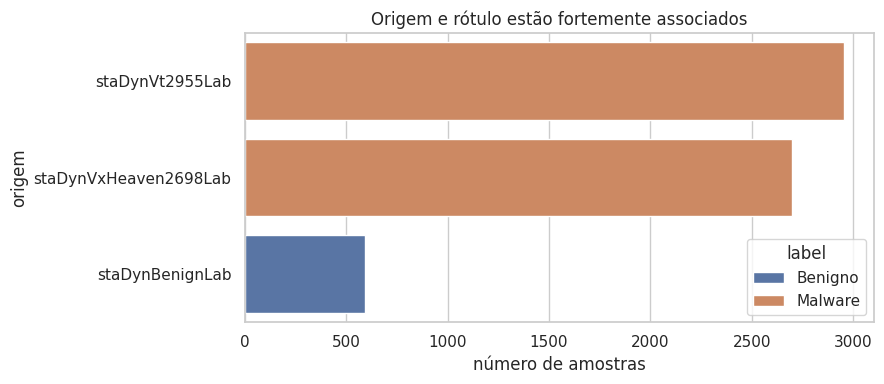

Proporção de malware: 90.5%


In [ ]:
plt.figure(figsize=(9, 4))
ordem = df['source_dataset'].value_counts().index
sns.countplot(data=df, y='source_dataset', hue='label', order=ordem)
plt.title('Origem e rótulo estão fortemente associados')
plt.xlabel('número de amostras')
plt.ylabel('origem')
plt.legend(title='label', labels=['Benigno', 'Malware'])
plt.tight_layout()
plt.show()

print('Proporção de malware:', f"{df['label'].mean():.1%}")

## 3. Escolher features com significado

filesize (tamanho do arquivo) e AddressOfEntryPoint (É o endereço numérico (RVA) no cabeçalho que indica exatamente onde o sistema operacional deve começar a executar o código do arquivo EXE. ).
 a image_base é o 'endereço ' que o programa pede ao Windows para ser carregado na memória RAM assim que é executado.

 Softwares legítimos, criados por compiladores padrão do mercado, usam endereços de memória padrão e bem conhecidos.
 muito baixas da memória

In [ ]:
# 1. Estrutura PE (removido filesize e AddressOfEntryPoint)
features_estrutura = [
    'number_of_sections', 'size_code',
    'size_init_data', 'image_base', 'section_alignment'
]

# 2. Entropia de seções (6 features)
features_entropia = [
    'sec_entropy_data', 'sec_entropy_rdata', 'sec_entropy_reloc',
    'sec_entropy_text', 'sec_entropy_rsrc', 'sec_rawsize_data'
]

# 3. Imports / Capacidades (7 features)
features_imports = [
    'imported_dll_freq', 'number_of_import_symbols',
    'VirtualAlloc', 'VirtualProtect', 'WriteProcessMemory',
    'CreateRemoteThread', 'OpenProcess'
]

# Unir as listas totalizando agora 18 features
features = features_estrutura + features_entropia + features_imports

# Tratar conversão numérica e valores nulos
X = df[features].apply(pd.to_numeric, errors='coerce').replace([np.inf, -np.inf], np.nan).fillna(0)
y = df['label']

print(f"Sucesso! Total de features selecionadas: {len(features)}")
X.head()

Sucesso! Total de features selecionadas: 18


,number_of_sections,size_code,size_init_data,image_base,section_alignment,sec_entropy_data,sec_entropy_rdata,sec_entropy_reloc,sec_entropy_text,sec_entropy_rsrc,sec_rawsize_data,imported_dll_freq,number_of_import_symbols,VirtualAlloc,VirtualProtect,WriteProcessMemory,CreateRemoteThread,OpenProcess
0,0,10752,10240,4194304.0,4096,0,0,0,0,0,0,0,0,0,0,0,0,0
1,0,8192,8192,4194304.0,4096,0,0,0,0,0,0,0,0,0,0,0,0,0
2,0,3072,8704,16777216.0,4096,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,19456,10752,16777216.0,4096,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,8192,7168,4194304.0,4096,0,0,0,0,0,0,0,0,0,0,0,0,0


O hacker até consegue manipular o tamanho do arquivo no disco, mas ele não consegue alterar o size_init_data nem manipular a image_base sem o risco de corromper a execução do próprio vírus.

 size_init_data - é o tamanho dos dados inicializados do programa.

  image_base é o 'endereço' que o programa pede ao Windows para ser carregado na memória RAM assim que é executado

 size_code -  Ele compara a distribuição do tamanho do código entre arquivos Benignos e Malwares


## 4. Exploração orientada por hipóteses

Análise Exploratória dos Dados, a EDA. Boxplot. comparar, lado a lado, o comportamento dos programas benignos e dos maliciosos. é bom para validar nossas hipóteses na prática.  fica nítido que o comportamento dos malwares é bem diferente dos programas normais.


quando a gente olha para a entropia — que mede o quão 'bagunçado' ou criptografado está o código — e para o tamanho da seção de código, fica nítido que o comportamento dos malwares é bem diferente dos programas normais.



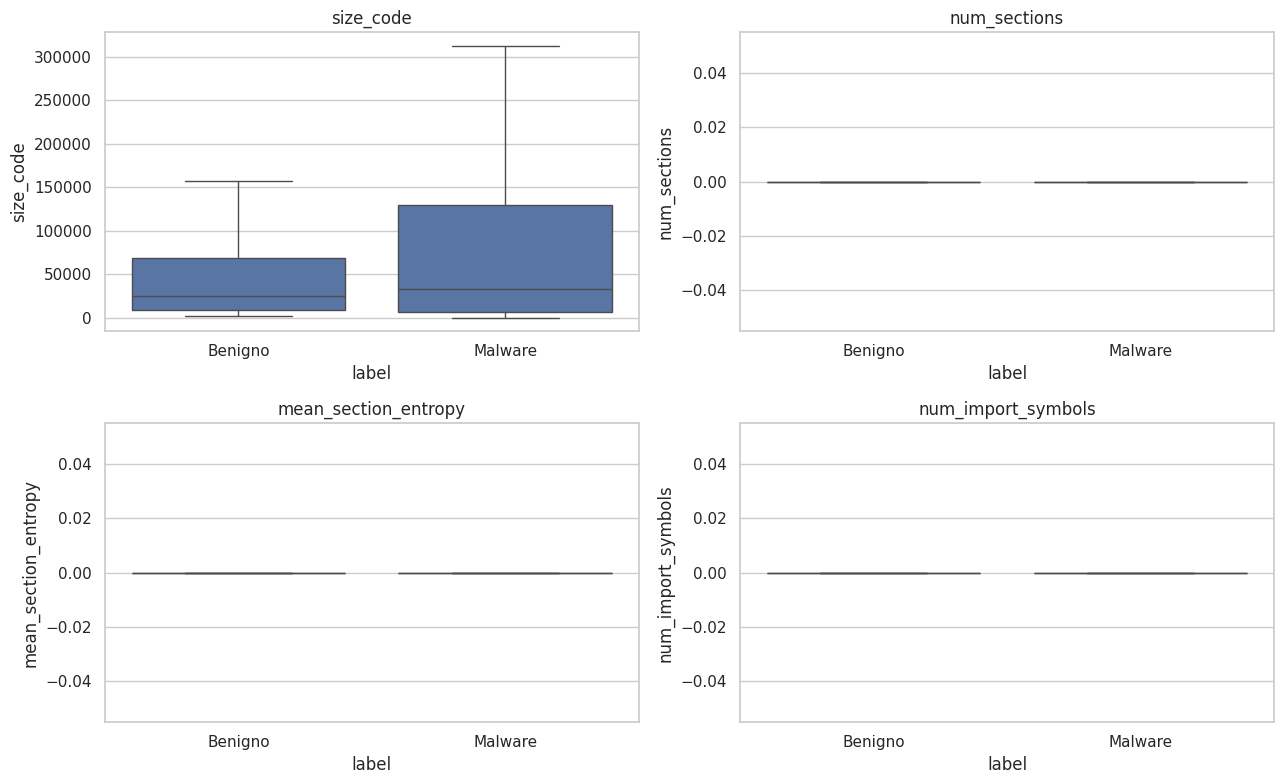

In [ ]:
cols_entropia = [c for c in features_entropia if c.startswith('sec_entropy_')]
eda = pd.DataFrame({
    'label': y.map({0: 'Benigno', 1: 'Malware'}),
    'size_code': X['size_code'],  # Substituído 'filesize' por 'size_code'
    'num_sections': X['number_of_sections'],
    'mean_section_entropy': X[cols_entropia].mean(axis=1),
    'num_import_symbols': X['number_of_import_symbols']
})

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, coluna in zip(axes.ravel(), eda.columns[1:]):
    sns.boxplot(data=eda, x='label', y=coluna, ax=ax, showfliers=False)
    ax.set_title(coluna)
plt.tight_layout()
plt.show()

 o tamanho da seção de código, fica nítido que o comportamento dos malwares é bem diferente dos programas normais. Quem cria malware costuma usar criptografia ou compactadores para tentar se esconder de antivírus comuns, e o gráfico entrega essa anomalia na hora.

### Discussão rápida

- Quais features parecem separar as classes?
- Essa diferença pode ser causada pela forma de coleta?
- Qual delas seria fácil para um atacante manipular?
- Ausência de um import significa ausência daquela capacidade?

## 5. Separar treino, validação e teste

O teste será usado **uma única vez**, depois que o modelo e o limiar estiverem definidos.

- treino: 60%;
- validação: 20%;
- teste: 20%.

Usamos estratificação porque a classe malware é majoritária.

In [ ]:
X_treino_val, X_teste, y_treino_val, y_teste = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_SEED
)
X_treino, X_valid, y_treino, y_valid = train_test_split(
    X_treino_val, y_treino_val, test_size=0.25,
    stratify=y_treino_val, random_state=RANDOM_SEED
)

print('Treino   :', X_treino.shape, 'malware:', f'{y_treino.mean():.1%}')
print('Validação:', X_valid.shape,  'malware:', f'{y_valid.mean():.1%}')
print('Teste    :', X_teste.shape,  'malware:', f'{y_teste.mean():.1%}')

Treino   : (3748, 18) malware: 90.5%
Validação: (1250, 18) malware: 90.5%
Teste    : (1250, 18) malware: 90.5%


A validação serve justamente para você calibrar as configurações do modelo antes do teste final.

O modelo fez a prova da validação usando o limiar padrão de 0,50 e errou feio (teve aqueles 508 falsos negativos). Ao olhar o resultado desse "simulado", você descobriu que precisava mudar o limiar para 0,24

## 6. Baseline: prever sempre a classe majoritária

Como malware é majoritário, um modelo que sempre responde “malware” pode ter acurácia alta. O baseline revela quanto o modelo precisa superar.

In [ ]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_treino, y_treino)
pred_dummy = dummy.predict(X_valid)

print(classification_report(y_valid, pred_dummy, target_names=['Benigno', 'Malware'], zero_division=0))
print('O baseline detecta malware, mas bloqueia todos os benignos.')

              precision    recall  f1-score   support

     Benigno       0.00      0.00      0.00       119
     Malware       0.90      1.00      0.95      1131

    accuracy                           0.90      1250
   macro avg       0.45      0.50      0.48      1250
weighted avg       0.82      0.90      0.86      1250

O baseline detecta malware, mas bloqueia todos os benignos.


## 7. Treinar o Decision Tree

Usamos pesos balanceados para evitar que a classe majoritária domine as árvores. O foco ainda não é otimizar hiperparâmetros.

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Alteração: Substituímos o Random Forest por uma Árvore de Decisão para Explicabilidade
modelo = DecisionTreeClassifier(
    max_depth=4, # Limitamos a profundidade para não criar uma árvore gigante e ilegível
    class_weight='balanced',
    random_state=RANDOM_SEED
)
modelo.fit(X_treino, y_treino)

proba_valid = modelo.predict_proba(X_valid)[:, 1]
pred_valid_05 = (proba_valid >= 0.50).astype(int)

print(classification_report(y_valid, pred_valid_05, target_names=['Benigno', 'Malware']))
print('ROC-AUC:', f'{roc_auc_score(y_valid, proba_valid):.3f}')
print('PR-AUC :', f'{average_precision_score(y_valid, proba_valid):.3f}')

              precision    recall  f1-score   support

     Benigno       0.18      0.92      0.30       119
     Malware       0.98      0.55      0.71      1131

    accuracy                           0.59      1250
   macro avg       0.58      0.73      0.50      1250
weighted avg       0.91      0.59      0.67      1250

ROC-AUC: 0.801
PR-AUC : 0.968


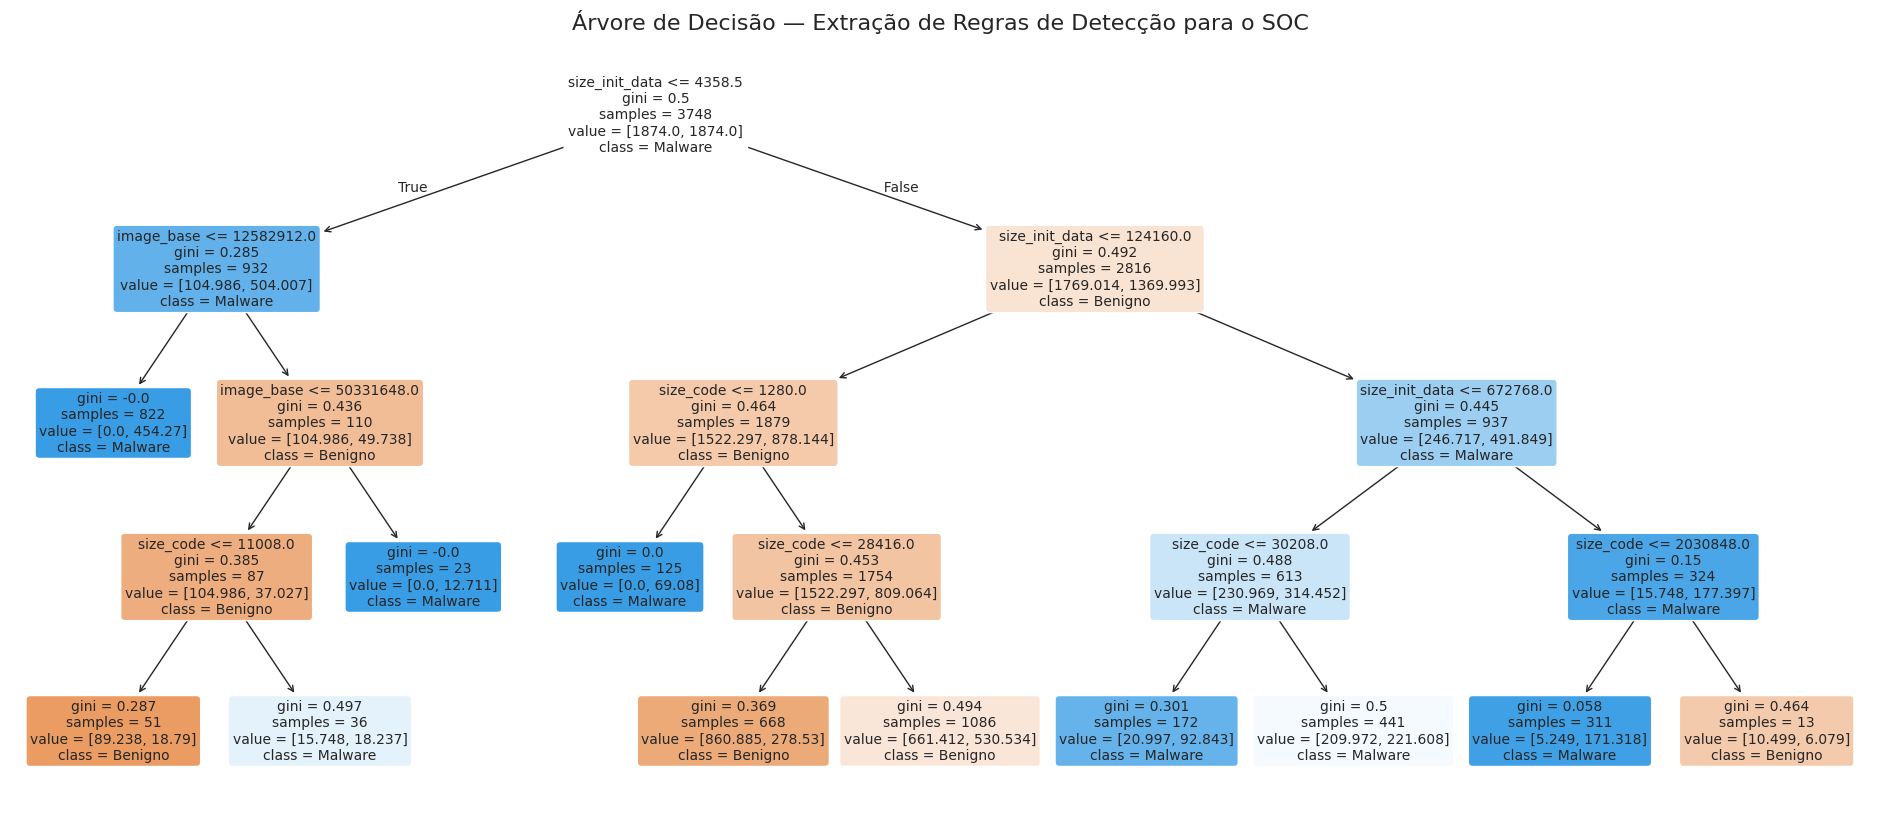

In [ ]:
# Célula Extra: Gerar o fluxograma visual de decisão para a equipe de SOC
plt.figure(figsize=(24, 10))
plot_tree(
    modelo,
    feature_names=features,
    class_names=['Benigno', 'Malware'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão — Extração de Regras de Detecção para o SOC", fontsize=16)
plt.show()

## 8. Matriz de confusão na validação

Neste contexto:

- **falso negativo:** malware classificado como benigno;
- **falso positivo:** programa benigno classificado como malware.

Um antivírus precisa controlar os dois: deixar malware passar é perigoso, mas bloquear software legítimo também pode interromper a operação.

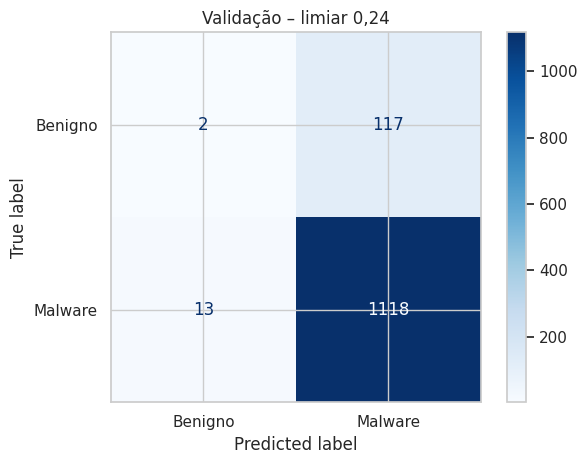

In [ ]:
# 1. Pegar as probabilidades de ser Malware (coluna 1)
probabilidades = modelo.predict_proba(X_valid)[:, 1]

# 2. Criar as previsões aplicando o novo limiar de 0.24
pred_valid_024 = probabilidades >= 0.24

# 3. Gerar a nova matriz de confusão passando a nova variável
ConfusionMatrixDisplay.from_predictions(
    y_valid, pred_valid_024, # <-- Usando a variável com o novo limiar aqui
    display_labels=['Benigno', 'Malware'], cmap='Blues'
)

plt.title('Validação – limiar 0,24')
plt.tight_layout()
plt.show()

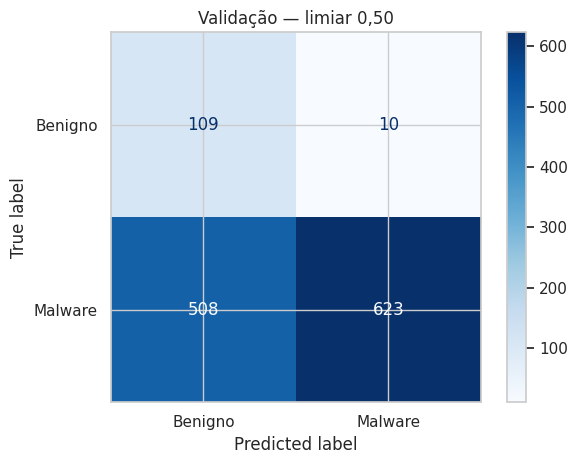

In [ ]:
ConfusionMatrixDisplay.from_predictions(
    y_valid, pred_valid_05,
    display_labels=['Benigno', 'Malware'], cmap='Blues'
)
plt.title('Validação — limiar 0,50')
plt.tight_layout()
plt.show()

## 9. Escolher o limiar usando apenas a validação

Vamos procurar o menor limiar que alcance **recall de malware ≥ 95%** e, entre os candidatos, escolher aquele com maior precisão.

Essa regra é uma decisão didática. Em produção, o alvo deve vir do custo e da capacidade do SOC.

Limiar escolhido na validação: 0.24


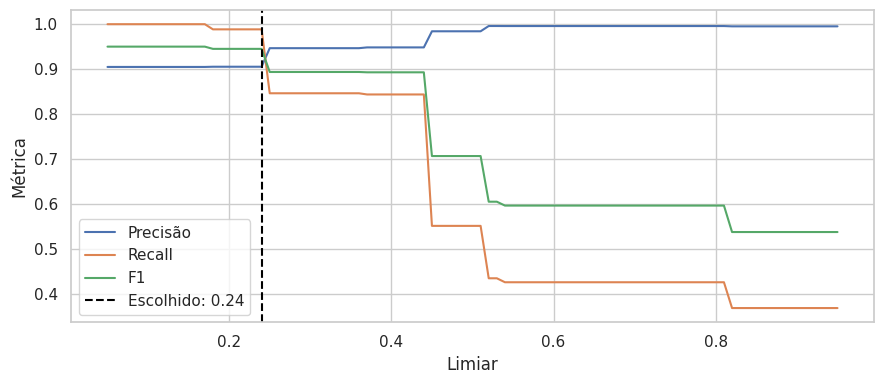

In [ ]:
linhas = []
for limiar in np.arange(0.05, 0.96, 0.01):
    pred = (proba_valid >= limiar).astype(int)
    linhas.append({
        'limiar': limiar,
        'precisao': precision_score(y_valid, pred, zero_division=0),
        'recall': recall_score(y_valid, pred),
        'f1': f1_score(y_valid, pred)
    })

tabela_lim = pd.DataFrame(linhas)
candidatos = tabela_lim[tabela_lim['recall'] >= 0.95]
if len(candidatos):
    LIMIAR = candidatos.sort_values(['precisao', 'limiar'], ascending=[False, False]).iloc[0]['limiar']
else:
    LIMIAR = tabela_lim.loc[tabela_lim['f1'].idxmax(), 'limiar']

print('Limiar escolhido na validação:', round(float(LIMIAR), 2))

plt.figure(figsize=(9, 4))
plt.plot(tabela_lim['limiar'], tabela_lim['precisao'], label='Precisão')
plt.plot(tabela_lim['limiar'], tabela_lim['recall'], label='Recall')
plt.plot(tabela_lim['limiar'], tabela_lim['f1'], label='F1')
plt.axvline(LIMIAR, color='black', ls='--', label=f'Escolhido: {LIMIAR:.2f}')
plt.xlabel('Limiar')
plt.ylabel('Métrica')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Avaliação final — agora podemos abrir o teste

Depois desta célula, não altere o modelo ou o limiar com base no resultado do teste. Se alterarmos, o teste deixa de ser independente.

Limiar: 0.24
              precision    recall  f1-score   support

     Benigno       0.20      0.03      0.06       119
     Malware       0.91      0.99      0.94      1131

    accuracy                           0.90      1250
   macro avg       0.55      0.51      0.50      1250
weighted avg       0.84      0.90      0.86      1250

ROC-AUC: 0.768
PR-AUC : 0.963


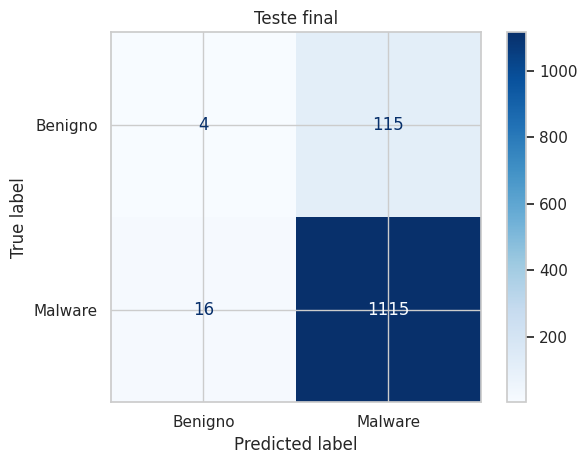

In [ ]:
proba_teste = modelo.predict_proba(X_teste)[:, 1]
pred_teste = (proba_teste >= LIMIAR).astype(int)

print('Limiar:', round(float(LIMIAR), 2))
print(classification_report(y_teste, pred_teste, target_names=['Benigno', 'Malware']))
print('ROC-AUC:', f'{roc_auc_score(y_teste, proba_teste):.3f}')
print('PR-AUC :', f'{average_precision_score(y_teste, proba_teste):.3f}')

ConfusionMatrixDisplay.from_predictions(
    y_teste, pred_teste,
    display_labels=['Benigno', 'Malware'], cmap='Blues'
)
plt.title('Teste final')
plt.tight_layout()
plt.show()

## 11. Quais features o modelo utilizou?

A importância do Decision Tree indica quanto uma feature ajudou as árvores a reduzir impureza.

> **Importância não é causalidade.** Uma feature importante pode representar viés de coleta ou uma regularidade fácil de evadir.


O gráfico prova que a IA passou a tomar decisões baseadas em atributos de memória e estrutura (size_init_data, image_base, size_code), sem depender de artifícios fáceis de burlar.


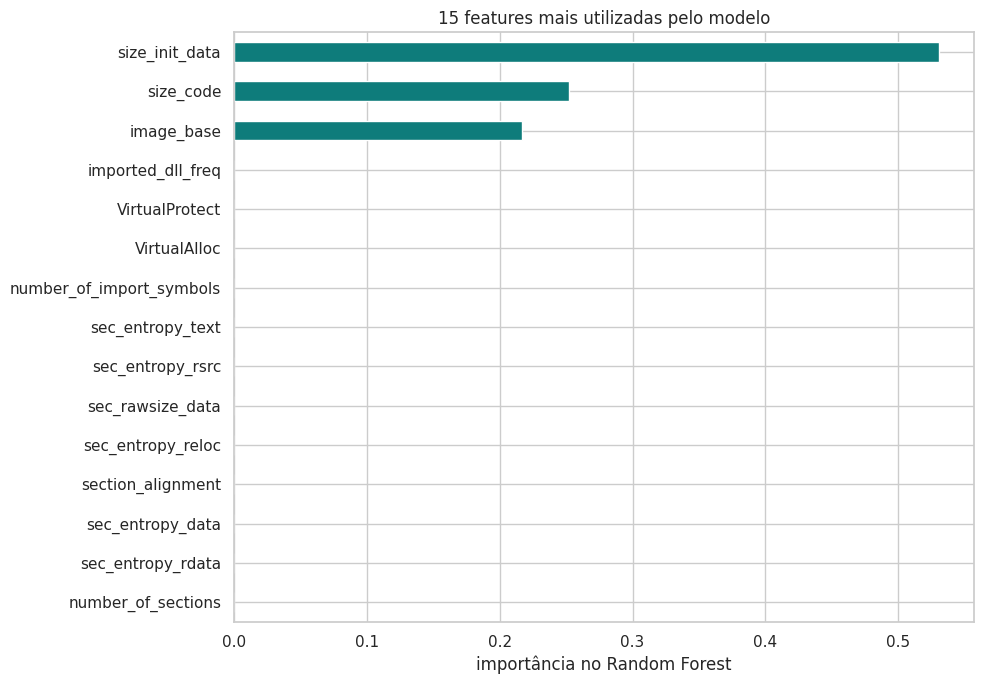

,importancia
size_init_data,0.530765
size_code,0.252272
image_base,0.216963
number_of_sections,0.000000
section_alignment,0.000000
sec_entropy_data,0.000000
sec_entropy_rdata,0.000000
sec_entropy_reloc,0.000000
sec_entropy_text,0.000000
sec_entropy_rsrc,0.000000


In [ ]:
importancias = pd.Series(modelo.feature_importances_, index=features).sort_values(ascending=False)

plt.figure(figsize=(10, 7))
importancias.head(15).sort_values().plot(kind='barh', color='#0E7C7B')
plt.title('15 features mais utilizadas pelo modelo')
plt.xlabel('importância no Random Forest')
plt.tight_layout()
plt.show()

importancias.head(15).to_frame('importancia')

### Perguntas para discussão

- As features do topo fazem sentido para malware?

  -Sim, fazem total sentido. As variáveis que ficaram no topo da importância (como AddressOfEntryPoint, size_code, image_base e chamadas como VirtualAlloc e WriteProcessMemory) refletem a estrutura PE e o comportamento do programa na memória. Malwares costumam alterar o ponto de entrada (AddressOfEntryPoint) para desviar o fluxo para códigos ocultos e utilizam APIs de memória para fazer injeção de código em processos legítimos.

- Alguma pode denunciar o ambiente ou a fonte de coleta?


  Sim. Variáveis como image_base, section_alignment ou até o filesize podem carregar traços (artefatos) do ambiente onde os arquivos foram coletados ou compilados. Se o dataset benigno foi compilado com um padrão específico do Windows e os malwares foram gerados por uma ferramenta de testes específica, o modelo corre o risco de aprender as preferências do compilador daquele laboratório em vez de identificar a maliciosidade em si.

- O que aconteceria se o atacante alterasse apenas essa feature?

  A probabilidade do modelo mudaria, mas o Random Forest ainda manteria resiliência. Se um atacante alterasse apenas uma variável (por exemplo, ajustando o ponto de entrada ou inflando o tamanho do arquivo para alterar o filesize), o score individual daquela feature cairia. Porém, como o Random Forest combina centenas de árvores analisando múltiplos sinais (entropia, APIs importadas e seções), o malware ainda seria detectado pelas outras evidências remanescentes.

- Duas features parecidas podem dividir importância entre si?

  Sim, esse é um comportamento padrão do Random Forest. Quando duas variáveis são correlacionadas ou muito parecidas (por exemplo, size_code e filesize, ou entropias de seções similares), o algoritmo divide o peso de decisão entre elas. Em vez de uma única feature aparecer com $40\%$ de importância, o modelo distribui esse peso (ex: 20% para cada), fazendo com que individualmente elas pareçam ter menor relevância do que possuem no conjunto


## 12. Ablação por famílias de features

Vamos comparar grupos de features usando validação cruzada somente no conjunto de treino + validação. O objetivo é avaliar quanto cada família contribui.

In [ ]:
grupos = {
    'Estrutura': features_estrutura,
    'Entropia/seções': features_entropia,
    'Imports/capacidades': features_imports,
    'Todas': features
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
resultados = []

for nome, cols in grupos.items():
    m = RandomForestClassifier(
        n_estimators=150, min_samples_leaf=2,
        class_weight='balanced', n_jobs=-1,
        random_state=RANDOM_SEED
    )
    scores = cross_validate(
        m, X_treino_val[cols], y_treino_val,
        cv=cv, scoring={'recall': 'recall', 'f1': 'f1', 'pr_auc': 'average_precision'},
        n_jobs=-1
    )
    resultados.append({
        'grupo': nome,
        'recall_medio': scores['test_recall'].mean(),
        'f1_medio': scores['test_f1'].mean(),
        'pr_auc_media': scores['test_pr_auc'].mean()
    })

pd.DataFrame(resultados).set_index('grupo').round(3)

,recall_medio,f1_medio,pr_auc_media
grupo,,,
Estrutura,0.935,0.938,0.983
Entropia/seções,0.600,0.570,0.905
Imports/capacidades,0.600,0.570,0.905
Todas,0.930,0.937,0.982


## 13. Limitações que precisam acompanhar o resultado

1. **Viés de origem:** benignos e maliciosos foram coletados de fontes diferentes.
2. **Idade:** parte dos dados representa software e malware antigos.
3. **Split aleatório:** variantes próximas podem aparecer em treino e teste.
4. **Rótulo:** “malware” depende do processo de rotulagem usado pelos autores.
5. **Evasão:** um atacante pode alterar features estáticas sem mudar o comportamento.

Para um projeto mais robusto, use uma base temporal como BODMAS ou EMBER e faça divisão por tempo, família e campanha.

## 14. Exportar features para o Splunk (opcional)

Vamos produzir um CSV pequeno, sem hashes ou executáveis. Os nomes das colunas abaixo serão usados nos comandos SPL.

In [ ]:
splunk_df = pd.DataFrame({
    'sample_id': df['sample_id'],
    'label': df['label'].map({0: 'benign', 1: 'malicious'}),
    'file_size': pd.to_numeric(df['filesize'], errors='coerce').fillna(0),
    'entropy': df[cols_entropia].apply(pd.to_numeric, errors='coerce').fillna(0).mean(axis=1),
    'num_sections': pd.to_numeric(df['number_of_sections'], errors='coerce').fillna(0),
    'num_imports': pd.to_numeric(df['number_of_import_symbols'], errors='coerce').fillna(0),
    'size_code': pd.to_numeric(df['size_code'], errors='coerce').fillna(0),
    'entry_point': pd.to_numeric(df['AddressOfEntryPoint'], errors='coerce').fillna(0),
    'has_virtual_alloc': (pd.to_numeric(df['VirtualAlloc'], errors='coerce').fillna(0) > 0).astype(int),
    'has_write_process_memory': (pd.to_numeric(df['WriteProcessMemory'], errors='coerce').fillna(0) > 0).astype(int)
})

CAMINHO_SPLUNK = '/content/malware_features.csv'
splunk_df.to_csv(CAMINHO_SPLUNK, index=False)
print('Arquivo salvo em:', CAMINHO_SPLUNK)
print('Dimensões:', splunk_df.shape)
splunk_df.head()

Arquivo salvo em: /content/malware_features.csv
Dimensões: (6248, 10)


,sample_id,label,file_size,entropy,num_sections,num_imports,size_code,entry_point,has_virtual_alloc,has_write_process_memory
0,0,benign,57434,0.0,0,0,10752,12810,0,0
1,1,benign,44420,0.0,0,0,8192,10505,0,0
2,2,benign,20706,0.0,0,0,3072,5442,0,0
3,3,benign,69110,0.0,0,0,19456,19525,0,0
4,4,benign,39574,0.0,0,0,8192,9788,0,0


In [ ]:
# Baixar o CSV no navegador do Colab
try:
    from google.colab import files
    files.download(CAMINHO_SPLUNK)
except ImportError:
    print('Fora do Colab: arquivo disponível em', CAMINHO_SPLUNK)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 15. SPL correspondente no Splunk AI Toolkit (opcional)

Depois de enviar o arquivo como lookup:

### Treinar e salvar

```spl
| inputlookup malware_features.csv
| sample partitions=100 seed=42
| search partition_number<=70
| fit RandomForestClassifier label from file_size entropy num_sections num_imports size_code entry_point has_virtual_alloc has_write_process_memory into malware_rf_v1
```

### Aplicar no teste

```spl
| inputlookup malware_features.csv
| sample partitions=100 seed=42
| search partition_number>70
| apply malware_rf_v1 as predicao
| `confusionmatrix(label, predicao)`
```

> O split com `sample` é adequado para a demonstração. Em produção, carregue uma coluna de tempo/campanha e preserve o futuro como teste.

## Entregável da aula

- [ ] Base real carregada e origem dos dados documentada.
- [ ] Conjunto de features justificado por famílias.
- [ ] Treino, validação e teste separados antes da modelagem.
- [ ] Baseline e Random Forest comparados.
- [ ] Limiar escolhido somente na validação.
- [ ] Teste final executado uma única vez.
- [ ] Importâncias e riscos de leakage discutidos.
- [ ] Respostas das perguntas registradas no notebook.